# 第 32 章：HJM、LIBOR 市场模型与多曲线

本笔记本重算本章的每个算例。
参数取自书中，每个数字都与书上印出的数值并列打印，某个数字一旦与书不符，一眼就能看出来。

| 节 | 重算的内容 | 例 |
|---|---|---|
| 1 | 曲线的因子结构，用主成分 | 32.1 |
| 2 | 瞬时波动率、它蕴含的布莱克波动率，以及由此自举出的水平 | 图 32.1 |
| 3 | 分段常数的自举，以及它在哪里失效 | (32.10)、(32.11) |
| 4 | 形状值多少：三种非标准的利率上限期权 | 32.2 |
| 5 | 终端相关性与瞬时相关性 | 32.3 |
| 6 | Rebonato 的互换期权近似及其权重 | 32.5 |
| 7 | 模拟互换期权：离散化，以及两个测度 | 32.4、32.5 |
| 8 | 为什么必须共用抽样 | 32.6 |

若只读一节，读第 7 节。它在两个不同的计价单位下为同一份互换期权定价，而正是这项检查
查出了本章初稿数字里的一个错误：恒定的偏移在差值中相消、在水平值中保留，因此单独
一套实现可能看上去对，其实是错的。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.stats import norm

N = norm.cdf
BAD = []

# The book's figure palette, from preamble.tex: exampleframe for the primary series,
# snapshotframe for the contrast one. Series are distinguished by dash pattern as well as
# color, because the book prints in grayscale.
BLUE, AMBER = "#28466E", "#78551E"
plt.rcParams.update({"figure.figsize": (6.4, 3.4), "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})


def show(label, got, printed, tol=5e-4):
    """Print a computed value beside the one the chapter prints. `tol` is absolute."""
    ok = abs(got - printed) <= tol
    if not ok:
        BAD.append(label)
    print("%-46s %12.4f   book %11.4f   %s" % (label, got, printed, "ok" if ok else "DIFFERS"))


# Equation (32.9), the Rebonato form, at the chapter's parameters throughout.
A_R, B_R, C_R, D_R = 0.045, 0.10, 0.75, 0.09


def sigma_inst(u):
    """Instantaneous volatility at time-to-reset u."""
    u = np.maximum(np.asarray(u, dtype=float), 0.0)
    return (A_R + B_R * u) * np.exp(-C_R * u) + D_R


def sigma_black(T, n=40001):
    """Equation (32.8): the Black volatility, the root-mean-square of the above over [0, T]."""
    u = np.linspace(0.0, float(T), n)
    return np.sqrt(np.trapezoid(sigma_inst(u) ** 2, u) / T)

## 1. 曲线的因子结构：例 32.1

把远期利率之间的相关性建模为 $\rho_{ij} = e^{-\beta|T_i-T_j|}$，取三十个一年期远期利率，
再读出特征值。这一形式是假设，而非发现。它的优点在于：对任何 $\beta \ge 0$ 都给出合法的相关矩阵，
无须检验可容许性。

这张表是对“三个因子解释曲线 99%”的纠正。这个数字来自*收益率*变动的主成分（Litterman 与 Scheinkman 得到约 98%）；
收益率是远期利率在其期限内的平均，相邻收益率的联动因此远强于远期利率。而对利差期权所依赖的远期利率相关性，若采用这一假定形式，当 $\beta$ 取 0.05 到 0.10 时，三个因子的解释比例
为 78%–89%。把同一矩阵平均成收益率后，这一比例为 98.7%–99.4%；单元格最后几行显示，
三个因子只保留十年期减两年期互换利差波动率的一半左右。

In [2]:
def corr(n, beta, floor=0.0):
    T = np.arange(1, n + 1, dtype=float)
    return floor + (1.0 - floor) * np.exp(-beta * np.abs(T[:, None] - T[None, :]))


def cum_share(n, beta, floor=0.0, k=5):
    """Cumulative share of variance explained by the leading k factors, in percent."""
    w = np.linalg.eigvalsh(corr(n, beta, floor))[::-1]
    return 100.0 * np.cumsum(w[:k]) / w.sum()


BOOK = {0.02: (82.8, 92.5, 95.3, 96.6, 97.4), 0.05: (64.8, 82.2, 88.6, 91.7, 93.5),
        0.10: (46.6, 68.1, 78.3, 83.9, 87.3), 0.20: (28.9, 49.0, 61.9, 70.2, 75.9)}
print("%-6s %8s %8s %8s %8s %8s" % ("beta", "1 fac", "2", "3", "4", "5"))
for beta, row in BOOK.items():
    got = cum_share(30, beta)
    print("%-6.2f " % beta + " ".join("%7.1f%%" % g for g in got))
print()
for beta, row in BOOK.items():
    for j, want in enumerate(row):
        show("beta %.2f, %d factor(s), %%" % (beta, j + 1), cum_share(30, beta)[j], want, 0.05)

# A factor count describes a strip, not a curve: the number of forwards moves it.
print()
for n, want in ((10, 85.5), (30, 64.8), (40, 57.5)):
    show("beta 0.05, one factor on %d forwards" % n, cum_share(n, 0.05)[0], want, 0.05)

# A far-end floor is itself a common factor, so it lifts every entry -- and 92% is still not 99%.
got = cum_share(30, 0.05, floor=0.3)
show("floor 0.3, one factor", got[0], 75.2, 0.05)
show("floor 0.3, three factors", got[2], 92.0, 0.05)

# The same matrix averaged into yields: one assumed form gives both the 78-89% and the 99%.
print()
AVG = np.tril(np.ones((30, 30))) / np.arange(1, 31)[:, None]     # a yield averages the forwards
for beta, want in ((0.05, 99.4), (0.10, 98.7)):
    Y = AVG @ corr(30, beta) @ AVG.T
    sd = np.sqrt(np.diag(Y))
    eig = np.linalg.eigvalsh(Y / np.outer(sd, sd))[::-1]
    show("yields, three factors, beta %.2f, %%" % beta, 100 * eig[:3].sum() / eig.sum(), want, 0.05)


def spread_kept(K, beta):
    """Share of a 10y-less-2y swap spread's volatility left by a rank-K correlation matrix.

    Unit volatilities and annuity weights on a flat 3% curve; rows are renormalized, as an
    implementation does, so that every forward keeps its own variance.
    """
    C = corr(30, beta)
    val, vec = np.linalg.eigh(C)
    B = vec[:, ::-1][:, :K] * np.sqrt(val[::-1][:K])
    B = B / np.linalg.norm(B, axis=1, keepdims=True)
    d = 1.03 ** -np.arange(1.0, 31.0)
    c = np.where(np.arange(30) < 10, d, 0.0) / d[:10].sum() - np.where(np.arange(30) < 2, d, 0.0) / d[:2].sum()
    return 100 * np.sqrt((c @ B @ B.T @ c) / (c @ C @ c))


# Three factors explain most of the variance and keep half of the spread: the form's kink at
# zero separation spreads the relative movement across many factors, so test the rank on the spread.
print()
for K, beta, want in ((3, 0.05, 49.3), (3, 0.10, 46.4), (7, 0.05, 97.6), (7, 0.10, 98.7)):
    show("spread vol kept, %d factors, beta %.2f, %%" % (K, beta), spread_kept(K, beta), want, 0.05)

beta      1 fac        2        3        4        5
0.02      82.8%    92.5%    95.3%    96.6%    97.4%
0.05      64.8%    82.2%    88.6%    91.7%    93.5%
0.10      46.6%    68.1%    78.3%    83.9%    87.3%
0.20      28.9%    49.0%    61.9%    70.2%    75.9%

beta 0.02, 1 factor(s), %                           82.8307   book     82.8000   ok
beta 0.02, 2 factor(s), %                           92.4516   book     92.5000   ok
beta 0.02, 3 factor(s), %                           95.3071   book     95.3000   ok
beta 0.02, 4 factor(s), %                           96.6290   book     96.6000   ok
beta 0.02, 5 factor(s), %                           97.3873   book     97.4000   ok
beta 0.05, 1 factor(s), %                           64.8341   book     64.8000   ok
beta 0.05, 2 factor(s), %                           82.2097   book     82.2000   ok
beta 0.05, 3 factor(s), %                           88.5646   book     88.6000   ok
beta 0.05, 4 factor(s), %                           91.6890   book 

## 2. 瞬时波动率，与它蕴含的布莱克波动率：图 32.1

两条光滑曲线都是今天的取值，横轴都是上限单元自身的到期期限。两者能共用一根横轴，
靠的是时间齐次性：当 $t$ 从 0 走到 $T_k$ 时，自变量 $T_k - t$ 扫过 $[0, T_k]$，
因此，上限单元在存续期内经历的各个瞬时波动率，正是实线在其到期期限左侧的取值，
而虚线就是实线的累积均方根。

注意“尾部”对两者各自意味着什么。瞬时波动率确实趋向 $d_R = 9\%$。布莱克波动率也趋向同一个
9%，但慢得多，在图的右端（15 年处）仍有 10.8%。

点线台阶不是第三个输入，而是从虚线自举出来的。下面的单元格分三步完成。

1. 在逐年的上限单元到期期限 $T_k = k$（$k = 1, \dots, 10$）上，从虚线读出布莱克波动率。
2. 把每个波动率换算成总方差 $\sigma_k^{\text{Black},2}\,T_k$，因为在上限单元的存续期内，
   可以累加的是方差，而不是波动率。
3. 把相邻的总方差相减，即式 (32.11)。增量等于 $\hat\sigma_k^2\,\tau$，其中 $\tau$ 为一年，
   $k = 0$ 的项为零；增量的平方根就是该水平，在第 $k$ 年上画成平直的一段。

这些水平能画在同一根横轴上，靠的也是时间齐次性：$\hat\sigma_k$ 适用于还剩 $k$ 个计息期的时候，
因此位于从重置日往回数的第 $k$ 年上。第一个上限单元没有可减的项，所以第一级台阶在一年处与虚线相交。
增量又正是光滑形式在这一年内贡献的方差，所以每一级台阶都是实线在该年内的均方根，
台阶因此贴着实线而不是虚线。台阶止于十年，是因为本章的上限单元序列只到十年。

instantaneous peak, years out                        0.8833   book      0.8833   ok
instantaneous peak, %                               15.8741   book     15.8700   ok
instantaneous tail (60y), %                          9.0000   book      9.0000   ok


implied Black peak, %                               15.3891   book     15.3900   ok
implied Black at 15y, %                             10.8188   book     10.8200   ok
implied Black at 30y, %                              9.9511   book      9.9500   ok

T        instantaneous  Black         
1        15.85          15.26         
2        14.47          15.27         
5        10.28          13.46         
10       9.06           11.62         
15       9.00           10.82         
20       9.00           10.39         
30       9.00           9.95          

交易台若把报出的布莱克波动率当作该远期利率的瞬时波动率，
在 15 年处会偏差 1.82 个波动率点。

k    Black %    total var    increment    level %   
1    15.26      0.023296     0.023296     15.26     
2    15.27      0.046644     0.023348     15.28     
3    14.72      0.064988     0.018344     13.54     
4    14.06      0.079126     0.014137     11.89     
5    13.46      0.090608     0.011482     10.72     
6    12.95      0.100559     0.009951     9.98      
7    12.52

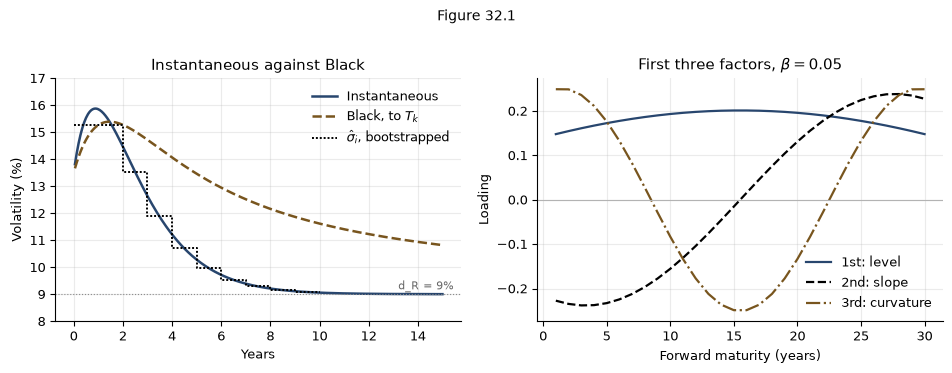

factor 1 sign changes                                0.0000   book      0.0000   ok
factor 2 sign changes                                1.0000   book      1.0000   ok
factor 3 sign changes                                2.0000   book      2.0000   ok


In [3]:
peak_u = 1.0 / C_R - A_R / B_R            # where the hump sits, analytically
show("instantaneous peak, years out", peak_u, 0.8833, 5e-4)
show("instantaneous peak, %", 100 * sigma_inst(peak_u), 15.87, 0.01)
show("instantaneous tail (60y), %", 100 * sigma_inst(60.0), 9.00, 0.01)

grid = np.linspace(0.02, 40.0, 2000)
bl = np.array([sigma_black(t) for t in grid])
show("implied Black peak, %", 100 * bl.max(), 15.39, 0.01)
show("implied Black at 15y, %", 100 * sigma_black(15.0), 10.82, 0.01)
show("implied Black at 30y, %", 100 * sigma_black(30.0), 9.95, 0.01)

print()
print("%-8s %-14s %-14s" % ("T", "instantaneous", "Black"))
for T in (1, 2, 5, 10, 15, 20, 30):
    print("%-8d %-14.2f %-14.2f" % (T, 100 * sigma_inst(T), 100 * sigma_black(T)))
print()
print("交易台若把报出的布莱克波动率当作该远期利率的瞬时波动率，")
print("在 15 年处会偏差 %.2f 个波动率点。"
      % (100 * (sigma_black(15.0) - sigma_inst(15.0))))

# ---------------------------------------------------------------- The bootstrapped levels
# Read the Black curve at the annual caplet maturities, turn each volatility into a total
# variance, and difference consecutive caplets. What the k-th caplet adds to the (k-1)-th is the
# variance of the k-th level, which is equation (32.11); with tau = 1 no division is left to do.
TAU = 1.0
K10 = np.arange(1, 11)
blk = np.array([sigma_black(float(k)) for k in K10])
total_var = blk ** 2 * K10                                  # equation (32.10), equal accruals
increment = np.diff(np.concatenate(([0.0], total_var)))     # equation (32.11)
hat = np.sqrt(increment / TAU)

print()
print("%-4s %-10s %-12s %-12s %-10s" % ("k", "Black %", "total var", "increment", "level %"))
for k in K10:
    print("%-4d %-10.2f %-12.6f %-12.6f %-10.2f"
          % (k, 100 * blk[k - 1], total_var[k - 1], increment[k - 1], 100 * hat[k - 1]))
print()

# A round trip, true by construction: it checks only that the printed 11.62 is the same number.
show("Black at 10y, rebuilt from the levels, %", 100 * np.sqrt(np.mean(hat ** 2)), 11.62, 0.01)
# Each level is the root-mean-square of the smooth form over its own year.
u3 = np.linspace(2.0, 3.0, 40001)
show("third level, rms of the smooth form, %",
     100 * np.sqrt(np.trapezoid(sigma_inst(u3) ** 2, u3)), 13.54, 0.01)

# ---------------------------------------------------------------- Figure 32.1
# Left: the instantaneous volatility and the Black volatility it implies, both indexed by the
# caplet's own maturity -- which they can share only because the form is time-homogeneous --
# and the levels just bootstrapped, each drawn flat over its own period.
# Right: the first three eigenvectors of the correlation matrix, the level, slope and curvature
# that Litterman and Scheinkman named.
x = np.linspace(0.05, 15.0, 400)
inst = 100 * sigma_inst(x)
blk_curve = np.array([100 * sigma_black(t) for t in x])

w, V = np.linalg.eigh(corr(30, 0.05))
order = np.argsort(w)[::-1]
mats = np.arange(1, 31)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(9.6, 3.6))
axL.plot(x, inst, color=BLUE, lw=1.8, label="Instantaneous")
axL.plot(x, blk_curve, color=AMBER, lw=1.8, ls="--", label="Black, to $T_k$")
axL.step(np.arange(0, 11), 100 * np.concatenate((hat[:1], hat)), where="pre", color="black",
         lw=1.4, ls=(0, (1, 1)), label=r"$\hat{\sigma}_i$, bootstrapped")
axL.axhline(100 * D_R, color="0.55", lw=0.8, ls=":")
axL.annotate("d_R = 9%", xy=(13.2, 100 * D_R + 0.18), color="0.4", fontsize=8)
axL.set_xlabel("Years"); axL.set_ylabel("Volatility (%)")
axL.set_title("Instantaneous against Black"); axL.set_ylim(8, 17); axL.legend(frameon=False)

for k, (c, ls, lab) in enumerate(((BLUE, "-", "1st: level"),
                                  ("black", "--", "2nd: slope"),
                                  (AMBER, "-.", "3rd: curvature"))):
    v = V[:, order[k]]
    if v.sum() < 0:
        v = -v
    axR.plot(mats, v, color=c, ls=ls, lw=1.6, label=lab)
axR.axhline(0.0, color="0.7", lw=0.8)
axR.set_xlabel("Forward maturity (years)"); axR.set_ylabel("Loading")
axR.set_title(r"First three factors, $\beta = 0.05$"); axR.legend(frameon=False)
fig.suptitle("Figure 32.1", y=1.02, fontsize=10)
plt.tight_layout(); plt.show()

# The panel's readings, checked rather than eyeballed: the first eigenvector is positive
# throughout, the second changes sign once, the third twice.
for k, want in enumerate((0, 1, 2)):
    v = V[:, order[k]]
    signs = np.sum(np.diff(np.sign(v)) != 0)
    show("factor %d sign changes" % (k + 1), float(signs), float(want), 0.5)

## 3. 分段常数的自举：式 (32.10) 与 (32.11)

不用光滑函数，而把 $\sigma_k(t)$ 取为分段常数（每个计息期一个水平），且保持时间齐次。
用 $\hat\sigma_i$ 记还剩 $i$ 个计息期时的水平。于是方差恒等式中的积分变成求和，
将相邻上限单元相减即可反解：每个上限单元提供一个新的水平，不需要优化器，
对上限单元序列的拟合按构造就是精确的。第 2 节已用它画出图中的点线台阶，这里把各水平与书中的表格逐一核对。

即使两种设定对每个上限单元都一致，作为函数，两者的形状也相差很大：瞬时水平降到 9.1%，
而它们所复现的上限单元波动率只降到 11.6%，因为每个上限单元波动率都在整个存续期内
对瞬时波动率取了平均。

只有计息期等长时，式 (32.11) 才能归结为这一次相减：第 32.7 节发现，对一年与六个月交替的序列
仍用此式，会把 $\hat\sigma_2$ 算错三分之一。单元格最后几行衡量的是一个相关的陷阱，即把某个水平
配到错误的计息期上，这会把上限单元的总方差算错至多 5%。

In [4]:
BOOK_HAT = (15.26, 15.28, 13.54, 11.89, 10.72, 9.98, 9.54, 9.29, 9.16, 9.08)
BOOK_BLK = (15.26, 15.27, 14.72, 14.06, 13.46, 12.95, 12.52, 12.16, 11.86, 11.62)
print("%-22s" % "Periods to reset" + "".join("%7d" % k for k in K10))
print("%-22s" % "sigma-hat, inst" + "".join("%7.2f" % (100 * h) for h in hat))
print("%-22s" % "Caplet Black vol" + "".join("%7.2f" % (100 * b) for b in blk))
print()
for i in range(10):
    show("sigma-hat, %2d periods to reset" % (i + 1), 100 * hat[i], BOOK_HAT[i], 0.01)
for i in range(10):
    show("caplet Black vol, T = %2d" % (i + 1), 100 * blk[i], BOOK_BLK[i], 0.01)

# The condition on (32.11), and the size of the error from ignoring it. Period m runs for
# tau_{m-1} and carries the level with k-m+1 periods still to run -- that pairing is the content
# of (32.10), and getting it wrong is the easy mistake.
print()
TAUS = [1.0, 0.5] * 6
LEV = [0.16, 0.15, 0.14, 0.13, 0.12, 0.11, 0.105, 0.10, 0.098, 0.095]
worst = 0.0
for k in range(10):
    right = sum(LEV[(k - m + 1) - 1] ** 2 * TAUS[m] for m in range(k + 1))
    wrong = sum(LEV[i] ** 2 * TAUS[i] for i in range(k + 1))
    worst = max(worst, abs(wrong / right - 1.0))
print("计息期不等长时：把某个水平配到错误的计息期上，会把一个上限单元的")
print("总方差算错至多 %.2f%%，折成波动率是 %.1f%%。" % (100 * worst,
      100 * (np.sqrt(1 + worst) - 1)))

Periods to reset            1      2      3      4      5      6      7      8      9     10
sigma-hat, inst         15.26  15.28  13.54  11.89  10.72   9.98   9.54   9.29   9.16   9.08
Caplet Black vol        15.26  15.27  14.72  14.06  13.46  12.95  12.52  12.16  11.86  11.62

sigma-hat,  1 periods to reset                      15.2631   book     15.2600   ok
sigma-hat,  2 periods to reset                      15.2800   book     15.2800   ok
sigma-hat,  3 periods to reset                      13.5440   book     13.5400   ok
sigma-hat,  4 periods to reset                      11.8901   book     11.8900   ok
sigma-hat,  5 periods to reset                      10.7155   book     10.7200   ok
sigma-hat,  6 periods to reset                       9.9755   book      9.9800   ok
sigma-hat,  7 periods to reset                       9.5388   book      9.5400   ok
sigma-hat,  8 periods to reset                       9.2914   book      9.2900   ok
sigma-hat,  9 periods to reset                  

## 4. 形状值多少：例 32.2

第 3 节的两种设定对每个上限单元都一致，因此只有收益取决于远期利率向量路径的产品才能区分它们。
本例取三种产品，它们的执行价或行权规则都不是事先固定的：**跳动上限**的执行价重置为刚观察到的利率
加一个利差；**粘性上限**的执行价重置为上一期封顶后的利率加一个利差；**灵活上限**只有最先到期时处于实值
的五个上限单元才支付。普通上限作为对照一同计算：两种设定按构造都复现其布莱克价值，
因此那里出现的任何差异都是数值误差。

两种设定在同一批抽样上、在终端测度 $Q^{T_{11}}$ 下一起模拟，每年 16 步，每步的协方差精确积分。
第二次运行改为在每步起点固定各个 $\sigma_k$，每年 4 步。这时普通上限这一对照出现偏差，
跳动上限的差异扩大到八倍，而跳动上限自身的数字看不出任何异样。

书中的表格使用另一个随机数生成器，因此下面的数字与书上并非逐位相同，每个数字都在四倍标准误差
之内与书核对。单元格最后几行检验光滑形式定价更高的原因：两种形式在每一期放入的方差相同，
但阶梯函数使相邻远期利率同步变动，相关性略高，而跳动上限和粘性上限实质上是以相邻两次定盘之差
为标的的期权。

In [5]:
# Example 32.2. Grid T_k = k, forwards flat at 5%, caplets on F_1..F_10, terminal measure Q^{T_11},
# the correlation of Example 32.1 at beta = 0.05, spread 25 bp, flexi limited to five exercises.
# Vanilla and flexi are struck at 5%; ratchet and sticky start from K_1 = F_0 + s = 5.25%.
NS_N, NS_F0, NS_S, NS_K, NS_FLEX = 10, 0.05, 0.0025, 0.05, 5
NS_RHO = corr(NS_N, 0.05)
NS_DISC = (1.0 + NS_F0) ** -(NS_N + 1)


def black_cap(K):
    """The vanilla cap as a sum of Black caplets, the control's known answer."""
    tot = 0.0
    for k in range(1, NS_N + 1):
        sd = np.sqrt(total_var[k - 1])
        d1 = (np.log(NS_F0 / K) + 0.5 * sd * sd) / sd
        tot += (1.0 + NS_F0) ** -(k + 1) * (NS_F0 * N(d1) - K * N(d1 - sd))
    return 100 * tot


def step_covariances(steps_per_year, frozen):
    """Per step: the first live forward, then (volatilities, Cholesky factor) for each form.

    frozen=False integrates the smooth form's covariance over the step; frozen=True holds each
    sigma_k at its value at the start of the step. The step form is constant within a period.
    """
    dt = 1.0 / steps_per_year
    out = []
    for s in range(NS_N * steps_per_year):
        t0 = s * dt
        m = int(t0 + 1e-12)
        T = np.arange(m + 1, NS_N + 1, dtype=float)      # resets of the live forwards
        R = NS_RHO[m:, m:]
        if frozen:
            v0 = sigma_inst(T - t0)
            c0 = R * np.outer(v0, v0)
        else:
            u = np.linspace(t0, t0 + dt, 41)
            sg = sigma_inst(T[:, None] - u[None, :])
            c0 = R * (np.trapezoid(sg[:, None, :] * sg[None, :, :], u, axis=2) / dt)
            v0 = np.sqrt(np.diag(c0))
        v1 = hat[:NS_N - m]
        c1 = R * np.outer(v1, v1)
        out.append((m, (v0, np.linalg.cholesky(c0)), (v1, np.linalg.cholesky(c1))))
    return out


def nonstandard_caps(steps_per_year, frozen=False, pairs=48000, seed=32):
    """Both forms on the same draws. Columns: ratchet, sticky, flexi, vanilla."""
    rng = np.random.default_rng(seed)
    dt = 1.0 / steps_per_year
    P = 2 * pairs
    lnF = np.full((2, P, NS_N), np.log(NS_F0))
    vals = np.zeros((2, P, 4))
    kr = np.full((2, P), NS_F0 + NS_S)
    ks = kr.copy()
    used = np.zeros((2, P), dtype=int)
    for s, (m, *forms) in enumerate(step_covariances(steps_per_year, frozen)):
        e = rng.standard_normal((pairs, NS_N - m))
        e = np.vstack([e, -e])                           # antithetic
        upper = np.triu(NS_RHO[m:, m:], 1)
        for q, (vol, L) in enumerate(forms):
            F = np.exp(lnF[q][:, m:])
            lam = F * vol / (1.0 + F)
            mu = -vol * (lam @ upper.T)                  # terminal measure: forwards beyond k
            lnF[q][:, m:] += (mu - 0.5 * vol ** 2) * dt + np.sqrt(dt) * (e @ L.T)
            if abs((s + 1) * dt - (m + 1)) < 1e-9:       # F_{m+1} fixes at T_{m+1}
                F = np.exp(lnF[q][:, m:])
                rate = F[:, 0]
                defl = (1.0 + F[:, 1:]).prod(axis=1)     # payoff over the terminal numeraire
                vals[q, :, 0] += np.maximum(rate - kr[q], 0.0) * defl
                kr[q] = rate + NS_S
                vals[q, :, 1] += np.maximum(rate - ks[q], 0.0) * defl
                ks[q] = np.minimum(rate, ks[q]) + NS_S
                pay = (rate > NS_K) & (used[q] < NS_FLEX)
                vals[q, :, 2] += np.where(pay, rate - NS_K, 0.0) * defl
                used[q] += pay
                vals[q, :, 3] += np.maximum(rate - NS_K, 0.0) * defl
    pv = 100 * NS_DISC * 0.5 * (vals[:, :pairs] + vals[:, pairs:])
    par, pw = pv.mean(axis=1)
    gap = pv[1] - pv[0]
    root = np.sqrt(pairs)
    return {"par": par, "pw": pw, "par_se": pv[0].std(axis=0, ddof=1) / root,
            "pw_se": pv[1].std(axis=0, ddof=1) / root, "diff": 100 * gap.mean(axis=0) / par,
            "diff_se": 100 * gap.std(axis=0, ddof=1) / root / par}


NAMES = ("Ratchet cap", "Sticky cap", "Flexi cap", "Vanilla cap")
BOOK_NS = ((1.8098, 1.8064, -0.19, 0.02), (3.6035, 3.5992, -0.12, 0.02),
           (2.7835, 2.7812, -0.08, 0.03), (4.1499, 4.1501, 0.01, 0.01))

show("vanilla cap, Black sum, per 100", black_cap(NS_K), 4.1414, 5e-5)
print()

res = nonstandard_caps(16)
print("%-14s %11s %11s %9s %8s" % ("", "Parametric", "Piecewise", "Diff %", "SE %"))
for i, name in enumerate(NAMES):
    print("%-14s %11.4f %11.4f %9.2f %8.2f"
          % (name, res["par"][i], res["pw"][i], res["diff"][i], res["diff_se"][i]))
print()

# Against the book, within four standard errors: a different generator, so not digit for digit.
# Two independent runs differ by sqrt(2) standard errors, so four of one run's is about 2.8 of their difference.
for i, name in enumerate(NAMES):
    par, pw, diff, se = BOOK_NS[i]
    show(name + ", parametric", res["par"][i], par, 4 * res["par_se"][i])
    show(name + ", piecewise", res["pw"][i], pw, 4 * res["pw_se"][i])
    show(name + ", difference %", res["diff"][i], diff, 4 * res["diff_se"][i])
    show(name + ", standard error %", res["diff_se"][i], se, 0.0051)
show("simulated vanilla against Black", res["par"][3], black_cap(NS_K), 4 * res["par_se"][3])
show("vanilla level standard error", res["par_se"][3], 0.013, 0.001)
print()

# The control that fails: sigma held at the start of the step, at four steps a year.
frz = nonstandard_caps(4, frozen=True)
print("每步起点固定 sigma，每年 4 步：")
show("ratchet difference %", frz["diff"][0], -1.55, 4 * frz["diff_se"][0])
show("vanilla difference %", frz["diff"][3], 0.31, 4 * frz["diff_se"][3])
print()


# Why the smooth form is dearer: the same variance in every period, but the step form moves
# neighboring forwards in lockstep, so F_k and F_{k+1} are more correlated under it over [0, T_k].
def neighbor_corr_smooth(k, n=20001):
    t = np.linspace(0.0, float(k), n)
    a, b = sigma_inst(k - t), sigma_inst(k + 1 - t)
    return np.trapezoid(a * b, t) / np.sqrt(np.trapezoid(a * a, t) * np.trapezoid(b * b, t))


def neighbor_corr_step(k):
    a, b = hat[:k], hat[1:k + 1]
    return (a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum())


print("%-10s %-10s %-10s" % ("k", "smooth", "step"))
for k in (2, 5, 9):
    sm, st = neighbor_corr_smooth(k), neighbor_corr_step(k)
    print("%-10d %-10.5f %-10.5f" % (k, sm, st))
    show("F_%d, F_%d: step above smooth (1 = yes)" % (k, k + 1), float(st > sm), 1.0, 0.5)

vanilla cap, Black sum, per 100                      4.1414   book      4.1414   ok



                Parametric   Piecewise    Diff %     SE %
Ratchet cap         1.8105      1.8071     -0.19     0.02
Sticky cap          3.6018      3.5980     -0.10     0.02
Flexi cap           2.7786      2.7776     -0.03     0.03
Vanilla cap         4.1536      4.1538      0.00     0.01

Ratchet cap, parametric                              1.8105   book      1.8098   ok
Ratchet cap, piecewise                               1.8071   book      1.8064   ok
Ratchet cap, difference %                           -0.1860   book     -0.1900   ok
Ratchet cap, standard error %                        0.0166   book      0.0200   ok
Sticky cap, parametric                               3.6018   book      3.6035   ok
Sticky cap, piecewise                                3.5980   book      3.5992   ok
Sticky cap, difference %                            -0.1044   book     -0.1200   ok
Sticky cap, standard error %                         0.0158   book      0.0200   ok
Flexi cap, parametric                

每步起点固定 sigma，每年 4 步：
ratchet difference %                                -1.5414   book     -1.5500   ok
vanilla difference %                                 0.3137   book      0.3100   ok

k          smooth     step      
2          0.99683    0.99816   
F_2, F_3: step above smooth (1 = yes)                1.0000   book      1.0000   ok
5          0.99787    0.99859   
F_5, F_6: step above smooth (1 = yes)                1.0000   book      1.0000   ok
9          0.99815    0.99866   
F_9, F_10: step above smooth (1 = yes)               1.0000   book      1.0000   ok


## 5. 终端相关性与瞬时相关性：例 32.3

把瞬时相关性设为 1，单独考察波动率*形状*的效应。答案是最多 0.6% 的去相关，
这看起来可以忽略。

但不该忽略。利差的方差是 $V_i + V_j - 2\rho\sqrt{V_iV_j}$，当 $\rho$ 很高时，
这个减法几乎完全抵消，残余误差因而被放大，平值期权的权利金也随之变动。

In [6]:
def ivar(Ti, H, Tj=None, n=20001):
    """Integral of sigma_i sigma_j over [0, H], with Tj = Ti when omitted."""
    u = np.linspace(0.0, H, n)
    a = sigma_inst(Ti - u)
    return np.trapezoid(a * (a if Tj is None else sigma_inst(Tj - u)), u)


print("%-6s %-6s %-10s %-12s" % ("T_i", "T_j", "horizon", "terminal corr"))
for Ti, Tj, H, want in ((2, 3, 2, 0.9968), (2, 5, 2, 0.9970), (2, 10, 2, 0.9993),
                        (5, 10, 5, 0.9936), (10, 20, 5, 0.9994)):
    got = ivar(Ti, H, Tj) / np.sqrt(ivar(Ti, H) * ivar(Tj, H))
    print("%-6d %-6d %-10s %-12.4f" % (Ti, Tj, "%dy" % H, got))
    show("T = %2d, %2d over %dy" % (Ti, Tj, H), got, want, 5e-4)

# The amplification: treating the instantaneous rho as the terminal one understates a spread's
# volatility, and the error grows as rho approaches one because the cancellation levers it.
print()
Vi, Vj, Cij = ivar(5, 5), ivar(10, 5), ivar(5, 5, 10)
term = Cij / np.sqrt(Vi * Vj)
for rho, want in ((0.85, 1.25), (0.99, 4.01)):
    true = Vi + Vj - 2.0 * rho * term * np.sqrt(Vi * Vj)
    naive = Vi + Vj - 2.0 * rho * np.sqrt(Vi * Vj)
    show("5y/10y spread vol understated at rho %.2f, %%" % rho,
         100 * (1.0 - np.sqrt(naive / true)), want, 0.01)

T_i    T_j    horizon    terminal corr
2      3      2y         0.9968      
T =  2,  3 over 2y                                   0.9968   book      0.9968   ok
2      5      2y         0.9970      
T =  2,  5 over 2y                                   0.9970   book      0.9970   ok
2      10     2y         0.9993      
T =  2, 10 over 2y                                   0.9993   book      0.9993   ok
5      10     5y         0.9936      
T =  5, 10 over 5y                                   0.9936   book      0.9936   ok
10     20     5y         0.9994      
T = 10, 20 over 5y                                   0.9994   book      0.9994   ok

5y/10y spread vol understated at rho 0.85, %         1.2492   book      1.2500   ok
5y/10y spread vol understated at rho 0.99, %         4.0090   book      4.0100   ok


## 6. Rebonato 的近似及其权重：例 32.5

这个近似冻结互换利率对各远期利率取平均时所用的权重，于是互换期权的布莱克方差成为各远期利率协方差的加权平均，
$\sigma_S^2 T \approx \sum_{i,j} w_i w_j \rho_{ij}\int_0^T \sigma_i\sigma_j\,dt$，权重
$w_k = \tau_k P(0,T_{k+1})F_k/(A(0)S(0))$；在平坦曲线上，它们就是年金因子的贴现权重，
也等于弹性 $(\partial S/\partial F_k)(F_k/S)$。

它们加总为一是恒等式，而不是归一化的结果：每一项 $\tau_k P(t,T_{k+1})F_k$ 等于
$P(t,T_k)-P(t,T_{k+1})$，求和裂项相消为 $A(t)S(t)$。加总不为一的权重向量，
说明贴现因子的递推出了错。

In [7]:
def swaption_weights(flat, n, T_exp, tau=1.0):
    """The annuity's discount weights, anchored at the option's expiration."""
    m0 = T_exp / tau
    d = np.array([(1.0 + flat * tau) ** -(m0 + k) for k in range(1, n + 1)])
    return d / d.sum()


def rebonato(flat, n, rho, T_exp, tau=1.0):
    """Black volatility of the swaption, from the frozen-weight sum of forward covariances."""
    resets = T_exp + np.arange(n, dtype=float) * tau
    w = swaption_weights(flat, n, T_exp, tau)
    R = np.full((n, n), rho)
    np.fill_diagonal(R, 1.0)
    C = np.array([[ivar(resets[i], T_exp, resets[j]) for j in range(n)] for i in range(n)])
    return 100 * np.sqrt((w[:, None] * w[None, :] * R * C).sum() / T_exp), w


AP1, W1 = rebonato(0.03, 5, 0.85, 1.0)
for k, want in enumerate((0.2120, 0.2058, 0.1998, 0.1940, 0.1884)):
    show("w_%d" % (k + 1), W1[k], want, 5e-4)
show("the weights sum to one", W1.sum(), 1.0000, 1e-12)
show("1y into 5y at 3%, approximation %", AP1, 12.5818, 5e-4)

AP2, W2 = rebonato(0.06, 10, 0.70, 5.0)
show("the weights sum to one, second trade", W2.sum(), 1.0000, 1e-12)
show("5y into 10y at 6%, approximation %", AP2, 9.0048, 5e-3)

w_1                                                  0.2120   book      0.2120   ok
w_2                                                  0.2058   book      0.2058   ok
w_3                                                  0.1998   book      0.1998   ok
w_4                                                  0.1940   book      0.1940   ok
w_5                                                  0.1884   book      0.1884   ok
the weights sum to one                               1.0000   book      1.0000   ok
1y into 5y at 3%, approximation %                   12.5818   book     12.5818   ok
the weights sum to one, second trade                 1.0000   book      1.0000   ok
5y into 10y at 6%, approximation %                   9.0048   book      9.0048   ok


## 7. 模拟互换期权：例 32.4 与 32.5

LMM 在 $\ln F_k$ 上推进。在终端测度 $Q^{T_N}$ 下，最长的远期没有漂移，
更早的每个远期利率都带有漂移

$$\mu_i = -\sigma_i \sum_{j>i} \rho_{ij}\,\sigma_j\,\frac{\tau F_j}{1+\tau F_j}$$

**这个单元格在两个不同的计价单位下为同一份互换期权定价，而这正是要点**。在到期远期测度
（以期权到期日到期的债券为计价单位）下，漂移反号并朝另一个方向求和，而到期时的计价单位是 1，因此没有依赖路径的
贴现因子。若两者一致，这套方法就是可靠的。若不一致，其中之一是错的；而*单独*一个实现
可以在 $\rho = 1$ 的对照下通过，却仍带着错误，因为在终端测度下，一个放错位置的贴现因子
会同时缩放价格与年金因子，从而在隐含波动率里相消。

这不是假想：本章初稿数字里的一处错误，正是这样被查出来的。

本章用四十万对对偶路径得出两项发现。离散化偏差确实存在，但消除它的成本很低：一年四步时为
6.2 个基点，到五十步就消失了。预测–校正没有可测量的差别，因为漂移是波动率的二阶量，
而扩散是一阶量。

**这个单元格只跑 5 万对路径，在这个规模上复现不了第一项发现**。每个水平的标准误差约为 5 个基点，
所以不同步数之间的差，以及例 32.5 下面印出的与 Rebonato 近似之间的差距，都是这个量级的噪声；
本章 0.1 与 1.3 个基点的结论依据的是后面带控制变量的模拟。这个单元格能确认的是第二项发现（因为
无论步数多少，欧拉格式与预测–校正都共用同一批抽样），以及两个测度在噪声范围内一致。

In [8]:
def implied_swaption(ann, S0, T, price):
    """Invert Black's swaption formula; at the money it is monotone in volatility."""
    def bs(v):
        d1 = 0.5 * v * np.sqrt(T)
        return ann * S0 * (N(d1) - N(-d1))
    return brentq(lambda v: bs(v) - price, 1e-6, 3.0, xtol=1e-14)


def simulate(flat, n, rho, T_exp, steps, pairs, measure="terminal", corrector=False,
             seed=32, tau=1.0, flat_sigma=None):
    """Black implied volatility of the at-the-money swaption, by log-Euler on the forwards."""
    resets = T_exp + np.arange(n, dtype=float) * tau
    R = np.full((n, n), rho)
    np.fill_diagonal(R, 1.0)
    chol = np.linalg.cholesky(R + 1e-14 * np.eye(n))
    m0 = T_exp / tau
    dfac = np.array([(1.0 + flat * tau) ** -(m0 + k) for k in range(1, n + 1)])
    ann0, P0_last, P0_exp = tau * dfac.sum(), dfac[-1], (1.0 + flat * tau) ** -m0
    dt = T_exp / steps
    rng = np.random.default_rng(seed)
    F = np.full((2 * pairs, n), flat)

    def drift(Fv, sig):
        lam = tau * Fv / (1.0 + tau * Fv)
        mu = np.zeros_like(Fv)
        if measure == "terminal":
            for i in range(n - 1):                       # longest forward is driftless
                mu[:, i] = -sig[i] * (R[i, i + 1:] * sig[i + 1:] * lam[:, i + 1:]).sum(axis=1)
        else:                                            # expiration-forward: sign and sum reverse
            for i in range(n):
                mu[:, i] = +sig[i] * (R[i, :i + 1] * sig[:i + 1] * lam[:, :i + 1]).sum(axis=1)
        return mu

    for s in range(steps):
        sig = (np.full(n, flat_sigma) if flat_sigma is not None
               else sigma_inst(resets - s * dt))
        z = rng.standard_normal((pairs, n)) @ chol.T
        z = np.vstack([z, -z])                           # antithetic
        diffusion = sig * np.sqrt(dt) * z - 0.5 * sig ** 2 * dt
        mu1 = drift(F, sig)
        if corrector:                                    # same draw in both passes
            pred = F * np.exp(mu1 * dt + diffusion)
            mu1 = 0.5 * (mu1 + drift(pred, sig))
        F = F * np.exp(mu1 * dt + diffusion)

    d = np.cumprod(1.0 / (1.0 + tau * F), axis=1)        # P(T_exp, T_exp + k tau)
    ann = tau * d.sum(axis=1)
    S = (tau * F * d).sum(axis=1) / ann
    payoff = ann * np.maximum(S - flat, 0.0)
    x = payoff / d[:, -1] if measure == "terminal" else payoff
    num = P0_last if measure == "terminal" else P0_exp
    return 100 * implied_swaption(ann0, flat, T_exp, num * x.mean())


PAIRS = 50000
# The chapter's tables used 400,000 antithetic pairs, where the standard error on the swaption's
# implied volatility is 1.8 basis points. At 50,000 it is nearly three times that, about 5, so the
# checks below allow a 0.15-percentage-point band, wide enough for a different seed. The two-measure
# check at the end shares its draws, so its 0.05 band does catch the twelve-basis-point error a draft
# of this chapter once carried.
SIM_TOL = 0.15

# The control first: at rho = 1 with a flat volatility the swaption's Black volatility must come
# back at that volatility, whatever the geometry. Run it under both measures.
print("对照：rho = 1，答案事先已知")
print("%-22s %-9s %-13s %-13s" % ("trade", "exact", "terminal", "expiration"))


for lbl, fl, n, Te, sg in (("1y into 5y", 0.03, 5, 1.0, 0.14),
                           ("5y into 10y", 0.06, 10, 5.0, 0.10)):
    a = simulate(fl, n, 1.0, Te, 100, PAIRS, "terminal", seed=5, flat_sigma=sg)
    b = simulate(fl, n, 1.0, Te, 100, PAIRS, "expiration", seed=5, flat_sigma=sg)
    print("%-22s %-9.4f %-13.4f %-13.4f" % (lbl, 100 * sg, a, b))
    show("%s control, terminal measure" % lbl, a, 100 * sg, SIM_TOL)
    show("%s control, expiration measure" % lbl, b, 100 * sg, SIM_TOL)

# Example 32.4: discretization, and the predictor-corrector against it.
print()
print("例 32.4：模拟误差实际在哪里")
print("%-7s %-13s %-13s %-12s" % ("steps", "Euler", "pred-corr", "vs approx"))
BOOK_324 = {4: (12.52, 12.52), 12: (12.53, 12.53), 50: (12.58, 12.58), 200: (12.58, 12.58)}
for steps, (we, wp) in BOOK_324.items():
    e = simulate(0.03, 5, 0.85, 1.0, steps, PAIRS, "terminal", False, seed=777)
    p = simulate(0.03, 5, 0.85, 1.0, steps, PAIRS, "terminal", True, seed=777)
    print("%-7d %-13.4f %-13.4f %-12.2f" % (steps, e, p, 100 * (e - AP1)))
    show("%3d steps, Euler" % steps, e, we, SIM_TOL)
    show("%3d steps, predictor-corrector" % steps, p, wp, SIM_TOL)

# Example 32.5: the approximation against a converged simulation, on both trades and both measures.
print()
print("例 32.5：这种不相容的代价")
print("%-20s %-12s %-13s %-13s" % ("trade", "approx", "terminal", "expiration"))
for lbl, fl, n, rho, Te, ap in (("1y into 5y at 3%", 0.03, 5, 0.85, 1.0, AP1),
                                ("5y into 10y at 6%", 0.06, 10, 0.70, 5.0, AP2)):
    a = simulate(fl, n, rho, Te, 200, PAIRS, "terminal", seed=21)
    b = simulate(fl, n, rho, Te, 200, PAIRS, "expiration", seed=21)
    print("%-20s %-12.4f %-13.4f %-13.4f" % (lbl, ap, a, b))
    print("%-20s %-12s gap %+.1f bp   gap %+.1f bp" % ("", "", 100 * (a - ap), 100 * (b - ap)))
    show("%s, two measures agree" % lbl, a - b, 0.0, 0.05)

对照：rho = 1，答案事先已知
trade                  exact     terminal      expiration   


1y into 5y             14.0000   14.0996       14.0939      
1y into 5y control, terminal measure                14.0996   book     14.0000   ok
1y into 5y control, expiration measure              14.0939   book     14.0000   ok


5y into 10y            10.0000   10.0321       10.0231      
5y into 10y control, terminal measure               10.0321   book     10.0000   ok
5y into 10y control, expiration measure             10.0231   book     10.0000   ok

例 32.4：模拟误差实际在哪里
steps   Euler         pred-corr     vs approx   


4       12.5833       12.5818       0.15        
  4 steps, Euler                                    12.5833   book     12.5200   ok
  4 steps, predictor-corrector                      12.5818   book     12.5200   ok


12      12.5536       12.5531       -2.82       
 12 steps, Euler                                    12.5536   book     12.5300   ok
 12 steps, predictor-corrector                      12.5531   book     12.5300   ok


50      12.5555       12.5553       -2.64       
 50 steps, Euler                                    12.5555   book     12.5800   ok
 50 steps, predictor-corrector                      12.5553   book     12.5800   ok


200     12.4970       12.4970       -8.48       
200 steps, Euler                                    12.4970   book     12.5800   ok
200 steps, predictor-corrector                      12.4970   book     12.5800   ok

例 32.5：这种不相容的代价
trade                approx       terminal      expiration   


1y into 5y at 3%     12.5818      12.6167       12.6157      
                                  gap +3.5 bp   gap +3.4 bp
1y into 5y at 3%, two measures agree                 0.0010   book      0.0000   ok


5y into 10y at 6%    9.0048       8.9780        8.9874       
                                  gap -2.7 bp   gap -1.7 bp
5y into 10y at 6%, two measures agree               -0.0095   book      0.0000   ok


### 带控制变量的模拟：例 32.5

5 万对普通路径分辨不出 1.3 个基点的误差与零，因此这个单元格用控制变量为两笔交易定价：
互换和以各远期利率为标的的期权，价值都精确已知，可以吸收大部分噪声。每步的协方差精确积分，漂移用预测–校正，
每次运行 20 万对路径，标准误差降到约 0.3 个基点。两种计价单位使用不同的抽样，结果一致。
本章的表格依据的是同一估计量、每次运行 168 万对路径的结果，因此这里的小差距要对照旁边的标准误差来读。

In [9]:
def controlled(flat, n, rho, T_exp, steps, pairs, measure, seed=32, chunk=50000):
    """Implied volatility and its standard error in bp, with the swap and an option on each
    forward as control variates. Annual accruals; each step's covariance integrated exactly."""
    resets = T_exp + np.arange(n, dtype=float)
    R = np.full((n, n), rho)
    np.fill_diagonal(R, 1.0)
    dt = T_exp / steps
    covs = []
    for s in range(steps):
        u = np.linspace(s * dt, (s + 1) * dt, 21)
        a = sigma_inst(resets[:, None] - u[None, :])
        covs.append(R * np.trapezoid(a[:, None, :] * a[None, :, :], u, axis=2))
    chols = [np.linalg.cholesky(C) for C in covs]
    terminal = measure == "terminal"
    drifts = [-np.triu(C, 1) if terminal else np.tril(C) for C in covs]

    # Exact control values, in units of the numeraire: 0 for the at-the-money swap, Black for
    # each option on F_k expiring with the swaption.
    dfac = (1.0 + flat) ** -(T_exp + np.arange(1, n + 1))
    num = dfac[-1] if terminal else (1.0 + flat) ** -T_exp
    sd = np.sqrt([ivar(r, T_exp) for r in resets])
    exact = np.concatenate(([0.0], dfac * flat * (2.0 * N(sd / 2.0) - 1.0) / num))

    rng = np.random.default_rng(seed)
    sx, sxx = np.zeros(n + 2), np.zeros((n + 2, n + 2))
    for _ in range(pairs // chunk):
        lnF = np.full((2 * chunk, n), np.log(flat))
        for C, L, D in zip(covs, chols, drifts):
            z = rng.standard_normal((chunk, n)) @ L.T
            z = np.vstack([z, -z])                       # antithetic
            half = 0.5 * np.diag(C)
            F = np.exp(lnF)
            mu = (F / (1.0 + F)) @ D.T
            Fp = np.exp(lnF + mu - half + z)             # predictor
            lnF = lnF + 0.5 * (mu + (Fp / (1.0 + Fp)) @ D.T) - half + z
        F = np.exp(lnF)
        P = np.cumprod(1.0 / (1.0 + F), axis=1)          # P(T_exp, T_exp + k)
        ann = P.sum(axis=1)
        S = (1.0 - P[:, -1]) / ann
        deflate = 1.0 / P[:, -1] if terminal else 1.0
        x = np.column_stack([ann * np.maximum(S - flat, 0.0) * deflate,
                             ann * (S - flat) * deflate]
                            + [P[:, k] * np.maximum(F[:, k] - flat, 0.0) * deflate
                               for k in range(n)])
        x = 0.5 * (x[:chunk] + x[chunk:])                # one row per antithetic pair
        sx += x.sum(axis=0)
        sxx += x.T @ x
    m = pairs // chunk * chunk
    mean = sx / m
    cov = sxx / m - np.outer(mean, mean)
    beta = np.linalg.solve(cov[1:, 1:], cov[1:, 0])
    est = mean[0] - beta @ (mean[1:] - exact)
    err = np.sqrt((cov[0, 0] - beta @ cov[1:, 0]) / m)
    ann0 = dfac.sum()
    vol = implied_swaption(ann0, flat, T_exp, num * est)
    up = implied_swaption(ann0, flat, T_exp, num * (est + err))
    return 100 * vol, 1e4 * (up - vol)


CV_PAIRS = 200000
print("%-20s %-12s %-20s %-20s" % ("trade", "approx", "terminal (s.e. bp)", "expiration (s.e. bp)"))
for lbl, fl, n, rho, Te, ap, want, gap in (("1y into 5y at 3%", 0.03, 5, 0.85, 1.0, AP1, 12.58, 0.1),
                                           ("5y into 10y at 6%", 0.06, 10, 0.70, 5.0, AP2, 8.99, 1.3)):
    a, ea = controlled(fl, n, rho, Te, 50, CV_PAIRS, "terminal", seed=41)
    b, eb = controlled(fl, n, rho, Te, 50, CV_PAIRS, "expiration", seed=42)
    print("%-20s %-12.4f %8.4f (%.2f) %11.4f (%.2f)" % (lbl, ap, a, ea, b, eb))
    show("%s, simulated %%" % lbl, 0.5 * (a + b), want, 0.01)
    show("%s, approximation high by, bp" % lbl, 100 * (ap - 0.5 * (a + b)), gap, 0.5)

trade                approx       terminal (s.e. bp)   expiration (s.e. bp)


1y into 5y at 3%     12.5818       12.5802 (0.29)     12.5793 (0.29)
1y into 5y at 3%, simulated %                       12.5798   book     12.5800   ok
1y into 5y at 3%, approximation high by, bp          0.2032   book      0.1000   ok


5y into 10y at 6%    9.0048         8.9920 (0.32)      8.9935 (0.31)
5y into 10y at 6%, simulated %                       8.9928   book      8.9900   ok
5y into 10y at 6%, approximation high by, bp         1.2050   book      1.3000   ok


## 8. 为什么必须共用抽样：例 32.6

这里只是简单的计算，却决定了实现上的一个问题。一份互换期权定价为 100.0000，用 100,000 条
路径，标准误差为 0.0500，而对曲线扰动一个基点使它变动 0.0480。

不共用抽样的代价不是两倍，而是路径数的 31,250 倍。

In [10]:
SE, BUMP, SE_CRN, PATHS = 0.0500, 0.0480, 0.0004, 100000

show("independent draws, se of the difference", SE * np.sqrt(2), 0.0707, 5e-4)
show("signal over noise, independent draws", BUMP / (SE * np.sqrt(2)), 0.68, 5e-3)
show("signal over noise, common random numbers", BUMP / SE_CRN, 120.0, 0.5)
show("the cost in paths, times", (SE * np.sqrt(2) / SE_CRN) ** 2, 31250.0, 50.0)
show("paths needed per bump, billions", (0.0707 / SE_CRN) ** 2 * PATHS / 1e9, 3.1, 0.05)

# And why the input count is what kills bump-and-revalue, rather than the path count.
print()
print("%-14s %-12s %-18s %-8s" % ("curve points", "vol points", "bump-and-revalue", "AAD"))
for m, v in ((50, 30), (80, 45), (120, 70)):
    print("%-14d %-12d %-18d %-8s" % (m, v, m + v + 1, "3 to 5"))
print()
print("账簿增加一种货币并不会使每次模拟变慢，而是使模拟次数")
print("增加。这正是伴随方法所消除的不对称。")

independent draws, se of the difference              0.0707   book      0.0707   ok
signal over noise, independent draws                 0.6788   book      0.6800   ok
signal over noise, common random numbers           120.0000   book    120.0000   ok
the cost in paths, times                         31250.0000   book  31250.0000   ok
paths needed per bump, billions                      3.1241   book      3.1000   ok

curve points   vol points   bump-and-revalue   AAD     
50             30           81                 3 to 5  
80             45           126                3 to 5  
120            70           191                3 to 5  

账簿增加一种货币并不会使每次模拟变慢，而是使模拟次数
增加。这正是伴随方法所消除的不对称。


## 重算的结论与两点收获

若下面的单元格报告每个数字都与本章一致，本笔记本中的数字便全部与书中一致。

有两个习惯值得养成，第一个来自第 7 节。模拟出的数字若要信得过，就
**在不同的计价单位下定价两次**，因为单独一套实现可以通过对照检验，却仍带着被测度掩盖的
错误。此外，**两个引用数字之差，对其中任何一个都构不成验证**：本章自己的验证脚本
曾经检查 $8.3278 - 9.0048 = -0.677$，那是对两处引用做减法，而不是对其中任何一个做检验，
其中一个数字错着的时候，它依然次次通过。

In [11]:
if BAD:
    print("有 %d 个数字与正文不符：" % len(BAD))
    for b in BAD:
        print("   ", b)
else:
    print("本笔记本中每个数字都与本章一致")

本笔记本中每个数字都与本章一致
